# Active Subspaces of a Two-Stage CMOS Op-Amp (AutoCkt)

__Keertana Settaluri__, University of California, Berkeley

__Ameer Haj-Ali__, University of California, Berkeley

__Qijing Huang__, University of California, Berkeley

__Kourosh Hakhamaneshi__, University of California, Berkeley

__Borivoje Nikolic__, University of California, Berkeley

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

This notebook runs in Python 3 with numpy, scipy and matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later. It reads stored data and takes well under a minute. The data were computed with the circuit simulator ngspice (version 42), which the notebook does not need; if `ngspice` is on the path, one cell re-simulates a few designs as a check.

In [1]:
%matplotlib inline
import shutil
import time

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import opamp_spice as op

SEED = 2020          # the only seed in this notebook (bootstrap); the data files used seeds 2020 and 2021
t_start = time.perf_counter()
names = list(op.NAMES)
labels = [r'$m_{p1}$', r'$m_{n1}$', r'$m_{p3}$', r'$m_{n3}$', r'$m_{n4}$', r'$m_{n5}$', r'$C_c$']

### Summary

Settaluri et al. [[1]][R1] train a reinforcement-learning agent (AutoCkt) to size a two-stage CMOS operational amplifier in a 45 nm predictive technology: six transistor sizes and a compensation capacitor, with targets on gain, unity-gain bandwidth, phase margin and bias current. We simulate the same circuit with ngspice over the paper's design box, treating the integer transistor multipliers as continuous and every input on a log scale, and compute active subspaces of the four specifications from finite-difference gradients. Supply current over the whole box, and unity-gain bandwidth among designs that meet the paper's lower gain target of 200 V/V, are each dominated by one direction, a ratio of device sizes that hand analysis predicts; the gain has a dominant direction, the second-stage current balance, inside a three-dimensional active subspace, and phase margin needs two directions, which hold only for high-gain designs.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ and is nearly constant along the other directions, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend, and a low-dimensional surrogate in $\mathbf y$ can stand in for $f$. We estimate $\mathbf C$ by the average of gradient outer products over the samples and assess the estimate with a bootstrap. See Constantine [[2]][R2] and Constantine, Dow and Wang [[3]][R3].

### The model

**Circuit** ([[1]][R1], Fig. 6; netlist adapted from the AutoCkt repository [[4]][R4]). A differential NMOS input pair $M_{n1}/M_{n2}$ with a PMOS current-mirror load $M_{p1}/M_{p2}$ and an NMOS tail source $M_{n3}$ forms the first stage; a PMOS common-source device $M_{p3}$ with an NMOS current-source load $M_{n5}$ forms the second; $M_{n4}$, diode-connected and fed by a 30 µA reference, sets the gate voltage of $M_{n3}$ and $M_{n5}$. A Miller capacitor $C_c$ connects the two stage outputs, and a 10 pF load sits at the output. Supply 1.2 V, input common mode 0.6 V. Every transistor is $W = 0.5$ µm, $L = 90$ nm, with a parallel multiplier $m$ (the paper's "width [1, 100, 1] × 0.5 µm" is implemented in the AutoCkt netlist as $m$ copies of a 0.5 µm device; AutoCkt builds its grid with `np.arange(1, 100, 1)`, i.e. $m$ = 1…99, and $C_c$ = 0.1…9.9 pF). Devices are BSIM4 (level 54) with the 45 nm Berkeley Predictive Technology Model card shipped with AutoCkt [[5]][R5].

**Simulation.** ngspice solves the DC operating point and an open-loop small-signal AC sweep from 1 Hz to 10 GHz with a unit differential input. With $H(f) = v_\mathrm{out}/v_\mathrm{in}$, the four quantities of interest are those of [[1]][R1] (Sec. III.B) as AutoCkt measures them:

$$
A = |H(1\,\mathrm{Hz})|, \qquad |H(f_u)| = 1, \qquad \mathrm{PM} = 180^\circ + \angle H(f_u), \qquad I = -\,i_{V_{DD}},
$$

the gain (V/V), unity-gain bandwidth $f_u$ (Hz), phase margin (degrees; phase unwrapped from 1 Hz) and the total supply current (A; the paper's "bias current, as a measure of power"). `opamp_spice.py` finds $f_u$ on a cubic spline in $\log f$ through 100 points per decade, and raises an error instead of returning a number when $f_u$ is undefined (gain at most 1, no crossing below 10 GHz, or several crossings). AutoCkt itself returns the lowest sweep frequency and $-180^\circ$ in those cases.

**Hand analysis** (standard two-stage op-amp results, not from [[1]][R1]) suggests what to expect. The currents are set by mirror ratios: $I \approx I_\mathrm{ref}(1 + m_{n3}/m_{n4} + m_{n5}/m_{n4})$. The open-loop output sits mid-rail, and both stages have high gain, only when the second-stage currents balance: $m_{p3}/m_{p1} = 2\,m_{n5}/m_{n3}$ for equal device lengths; away from this the output saturates at a rail and the gain collapses. The bandwidth is $f_u \approx g_{m1}/(2\pi C_c)$, and the phase margin is set by the second pole $g_{m,p3}/(2\pi C_L)$ and the right-half-plane zero $g_{m,p3}/(2\pi C_c)$ relative to $f_u$.

**Inputs.** The paper's design box, with each input on a log scale: the ranges span exactly two decades each, and the circuit depends on ratios of sizes, so we draw $\log_{10}$ of every input uniformly (the paper defines the box but no distribution; this is our choice). The integer grid of the paper is relaxed to real values; ngspice accepts a real multiplier, which scales every device current and capacitance by $m$. The table is printed from `opamp_spice.py`.

In [2]:
role = {'mp1': 'PMOS mirror load (mp1, mp2), first stage', 'mn1': 'NMOS input pair (mn1, mn2)',
        'mp3': 'PMOS common source, second stage', 'mn3': 'NMOS tail current source',
        'mn4': 'NMOS diode, bias reference', 'mn5': 'NMOS current-source load, second stage',
        'cc_pF': 'Miller compensation capacitor'}
autockt = [10, 38, 4, 9, 20, 60, 3]     # values in AutoCkt's two_stage_opamp.cir
print(f"{'input':6s} {'units':5s} {'lower':>6s} {'upper':>6s} {'AutoCkt netlist':>15s}  role")
for j, n in enumerate(names):
    print(f'{n:6s} {op.UNITS[j]:5s} {op.LOWER[j]:6g} {op.UPPER[j]:6g} {autockt[j]:15g}  {role[n]}')
print('held settings:', ', '.join(f'{k} = {v:g}' for k, v in op.HELD.items()))
n_m, n_c = len(np.arange(1, 100, 1)), len(np.arange(0.1e-12, 10.0e-12, 0.1e-12))   # AutoCkt's YAML grids
print(f"design-space size: paper 1e14 ('[1, 100, 1]', '[0.1, 10.0, 0.1]'); AutoCkt's np.arange grids give "
      f'{n_m} sizes per device and {n_c} capacitor values, {n_m}^6 x {n_c} = {n_m**6 * n_c:.2e}')

input  units  lower  upper AutoCkt netlist  role
mp1    1          1    100              10  PMOS mirror load (mp1, mp2), first stage
mn1    1          1    100              38  NMOS input pair (mn1, mn2)
mp3    1          1    100               4  PMOS common source, second stage
mn3    1          1    100               9  NMOS tail current source
mn4    1          1    100              20  NMOS diode, bias reference
mn5    1          1    100              60  NMOS current-source load, second stage
cc_pF  pF       0.1     10               3  Miller compensation capacitor
held settings: ibias_uA = 30, cload_pF = 10, vcm = 0.6, vdd = 1.2, reltol = 1e-09, points_per_decade = 100
design-space size: paper 1e14 ('[1, 100, 1]', '[0.1, 10.0, 0.1]'); AutoCkt's np.arange grids give 99 sizes per device and 99 capacitor values, 99^6 x 99 = 9.32e+13


The held settings are AutoCkt's, except two numerical ones chosen for smooth finite differences: the ngspice relative tolerance (AutoCkt uses the default $10^{-3}$) and the sweep density (AutoCkt: 10 points per decade). If ngspice is installed, the next cell simulates three designs and re-simulates two stored samples.

In [3]:
if shutil.which(op.NGSPICE):
    print(op.ngspice_version())
    for what, x in [('AutoCkt netlist values', autockt), ('centre of the log box (all m = 10, Cc = 1 pF)', [10] * 6 + [1]),
                    ('centre, mp3 = 20 (balanced: mp3/mp1 = 2 mn5/mn3)', [10, 10, 20, 10, 10, 10, 1])]:
        r = op.simulate(x, strict=False)
        extra = f"; ugbw, pm undefined: {r['error']}" if 'error' in r else f"; ugbw {r['ugbw']:.4g} Hz, pm {r['pm']:.2f} deg"
        print(f"{what}: gain {r['gain']:.4g} V/V, I {r['i_supply'] * 1e6:.2f} uA{extra}")
    for prefix in ('', 'gain200_'):
        Xs = np.loadtxt(prefix + 'inputs.csv', delimiter=',')[:2]
        Fs = np.loadtxt(prefix + 'outputs.csv', delimiter=',')[:2]
        Fn = np.array([op.qoi_vector(x, strict=False) for x in Xs])
        print(f'{prefix}outputs.csv rows 0-1 re-simulated: max relative difference '
              f'{np.nanmax(np.abs(Fn - Fs) / np.abs(Fs)):.1e}')
else:
    print('ngspice not found: re-simulation skipped (the analysis below reads only the stored files)')

ngspice-42 : Circuit level simulation program
AutoCkt netlist values: gain 0.6306 V/V, I 47.15 uA; ugbw, pm undefined: |H(1 Hz)| = 0.6306 <= 1: no unity-gain crossing
centre of the log box (all m = 10, Cc = 1 pF): gain 23.35 V/V, I 75.61 uA; ugbw 1.162e+07 Hz, pm 26.23 deg
centre, mp3 = 20 (balanced: mp3/mp1 = 2 mn5/mn3): gain 351.8 V/V, I 88.81 uA; ugbw 1.59e+07 Hz, pm 18.91 deg
outputs.csv rows 0-1 re-simulated: max relative difference 0.0e+00


gain200_outputs.csv rows 0-1 re-simulated: max relative difference 0.0e+00


The values in AutoCkt's netlist are not a working amplifier: the gain is below 1 and $f_u$ does not exist. At the centre of the log box the gain is modest, and doubling $m_{p3}$ to meet the balance condition raises it about fifteenfold, a first sign of the structure the active subspace finds below.

### Load data

`generate_data.py` (see `DATA.md`) wrote two sample sets, each with the four outputs and their gradients with respect to the physical inputs (central differences with step $10^{-4}$ in $\ln x_j$, 14 extra simulations per sample):

- **box**: 1000 independent log-uniform draws on the design box (seed 2020);
- **gain200**: the first 1000 log-uniform draws (seed 2021) whose gain is at least 200 V/V, the lower gain target of [[1]][R1]; that is, the same log-uniform distribution conditioned on $A \ge 200$.

In [4]:
data = {}
for name, prefix in [('box', ''), ('gain200', 'gain200_')]:
    X = np.loadtxt(prefix + 'inputs.csv', delimiter=',')                           # (M, 7) physical inputs
    F = np.loadtxt(prefix + 'outputs.csv', delimiter=',')                          # (M, 4) gain, ugbw, pm, I
    G = np.loadtxt(prefix + 'gradients.csv', delimiter=',').reshape(len(X), 4, 7)  # dF_k/dx_j, physical
    data[name] = (X, F, G)
    print(f'{name:8s} inputs {X.shape}, outputs {F.shape}, gradients {G.shape}; {open(prefix + "inputs.csv").readline()[2:].strip()}')
draws = int(open('gain200_inputs.csv').readline().split(' of ')[1].split()[0])

box      inputs (1000, 7), outputs (1000, 4), gradients (1000, 4, 7); Two-stage CMOS op-amp (Settaluri et al., DATE 2020), ngspice; 1000 log-uniform Monte Carlo samples on the design box, seed 2020; inputs


gain200  inputs (1000, 7), outputs (1000, 4), gradients (1000, 4, 7); Two-stage CMOS op-amp (Settaluri et al., DATE 2020), ngspice; the first 1000 of 12367 log-uniform Monte Carlo draws (seed 2021) with gain >= 200 V/V; inputs


**Coordinates.** The files hold physical inputs (multipliers, pF) and physical gradients. The analysis works in $z_j = \log_{10} x_j$ with `ac.Uniform` on the $\log_{10}$ box, which maps every input to $[-1, 1]$ by the same rule (each spans two decades). This cell converts once: $\partial q/\partial z_j = x_j \ln 10\, \partial q/\partial x_j$, and the outputs become gain in dB, $\log_{10} f_u$, PM in degrees and $\log_{10} I$.

For the box set the space is the sampling density. For the gain200 set it is only the normalization: conditioning on $A \ge 200$ makes the inputs neither uniform nor independent, and $\hat{\mathbf C}$ there is the average of $\nabla q\,\nabla q^T$ under the conditioned density. The last line of the cell measures how far the gain200 inputs are from the declared space. Its eigenvectors, and the sufficient summary plots on this set, are therefore over correlated inputs: a direction in $\mathbf x$ is not a direction along which the gain200 designs spread evenly.

In [5]:
LN10 = np.log(10.0)
space = ac.Uniform(np.log10(op.LOWER), np.log10(op.UPPER), names=[f'log10 {n}' for n in names])
QOIS = {'gain_dB': 'gain (dB)', 'log10_ugbw': r'$\log_{10} f_u$ (Hz)', 'pm': 'phase margin (deg)',
        'log10_I': r'$\log_{10} I$ (A)'}


def to_log(X, F, G):
    """z = log10 x; the four QoIs in dB / log10 / deg / log10 and their gradients in z."""
    Gz = G * X[:, None, :] * LN10                                       # d F_k / d z_j
    q = {'gain_dB': 20 * np.log10(F[:, 0]), 'log10_ugbw': np.log10(F[:, 1]),
         'pm': F[:, 2], 'log10_I': np.log10(F[:, 3])}
    dq = {'gain_dB': 20 / LN10 * Gz[:, 0] / F[:, [0]], 'log10_ugbw': Gz[:, 1] / (LN10 * F[:, [1]]),
          'pm': Gz[:, 2], 'log10_I': Gz[:, 3] / (LN10 * F[:, [3]])}
    return np.log10(X), q, dq


Z, q, dq = to_log(*data['box'])
Za, qa, dqa = to_log(*data['gain200'])
Fb, Fa = data['box'][1], data['gain200'][1]
undef = np.isnan(Fb[:, 1])
print(f'box: ugbw and pm undefined at {undef.sum()} of {len(Fb)} samples, all with gain <= 1 V/V: '
      f'{np.all(Fb[undef, 0] <= 1)}; defined at all {(~undef).sum()} with gain > 1')
print('box: gain (dB) percentiles 0, 10, 50, 90, 100:', np.round(np.percentile(q['gain_dB'], [0, 10, 50, 90, 100]), 1))
print(f'box: gain >= 200 V/V in {np.mean(Fb[:, 0] >= 200):.3f} of the samples; '
      f'gain200 set: {len(Fa)} accepted of {draws} draws, acceptance {len(Fa) / draws:.4f}')
print(f'gain200: ugbw [{Fa[:, 1].min():.3g}, {Fa[:, 1].max():.3g}] Hz, pm [{Fa[:, 2].min():.1f}, {Fa[:, 2].max():.1f}] deg, '
      f'pm < 0 at {np.sum(Fa[:, 2] < 0)}, pm >= 60 at {np.sum(Fa[:, 2] >= 60)}')
print(f'box: smallest defined ugbw {np.nanmin(Fb[:, 1]):.3g} Hz')
for name, Zs in [('box', Z), ('gain200', Za)]:
    xn = Zs - np.log10(op.LOWER * op.UPPER) / 2                       # normalized inputs in [-1, 1]
    xc = xn - xn.mean(axis=0)
    kurt = np.mean(xc**4, axis=0) / np.var(xn, axis=0)**2
    cr = np.corrcoef(xn.T)[~np.eye(7, dtype=bool)]
    bal = Zs[:, 2] + Zs[:, 3] - Zs[:, 0] - Zs[:, 5]                   # log10(mp3 mn3 / (mp1 mn5))
    print(f'{name:7s}: normalized-input kurtosis {kurt.min():.2f}-{kurt.max():.2f} (uniform 1.8), means '
          f'{xn.mean(axis=0).min():+.2f} to {xn.mean(axis=0).max():+.2f}, max |corr| {np.abs(cr).max():.3f}; '
          f'balance variable in [{bal.min():.3f}, {bal.max():.3f}], sd {bal.std():.3f}')

box: ugbw and pm undefined at 310 of 1000 samples, all with gain <= 1 V/V: True; defined at all 690 with gain > 1
box: gain (dB) percentiles 0, 10, 50, 90, 100: [-97.9 -16.1   8.6  42.4  52.6]
box: gain >= 200 V/V in 0.068 of the samples; gain200 set: 1000 accepted of 12367 draws, acceptance 0.0809
gain200: ugbw [1.48e+05, 2.27e+08] Hz, pm [-80.4, 86.8] deg, pm < 0 at 183, pm >= 60 at 72
box: smallest defined ugbw 9.63e+03 Hz
box    : normalized-input kurtosis 1.77-1.85 (uniform 1.8), means -0.01 to +0.04, max |corr| 0.071; balance variable in [-3.516, 3.673], sd 1.161
gain200: normalized-input kurtosis 1.76-2.20 (uniform 1.8), means -0.19 to +0.21, max |corr| 0.534; balance variable in [0.074, 1.087], sd 0.122


### Estimate the subspace

The gradients are central differences through ngspice, accurate to about $10^{-4}$ relative or better (`DATA.md`, "Accuracy"), so we use the gradient estimator (`estimator="as"`), $\hat{\mathbf C} = \frac1M\sum_i \nabla q_i \nabla q_i^T$ in normalized coordinates, with 500 bootstrap replicates. A relative gradient error $\epsilon$ perturbs $\hat{\mathbf C}$ by about $2\epsilon\lambda_1$, so eigenvalues below about $10^{-4}\lambda_1$ are at the resolution floor of these data and are not interpreted. Four analyses:

- gain (dB) and $\log_{10} I$ on the **box** set: both are defined at every design;
- $\log_{10} f_u$ and PM on the **gain200** set. On the box they exist only where the gain exceeds 1, and there they are dominated by designs barely above that threshold. For a one-pole response $|H| = 1$ at $f_u = f_p\sqrt{A^2 - 1}$, so $\partial\ln f_u/\partial\ln A = A^2/(A^2-1)$ grows without bound as $A \to 1$, although $f_u$ itself stays near the dominant pole (the smallest defined $f_u$ on the box is 9.63 kHz, printed above); the next cell shows the effect. Designs that meet the paper's gain target are the ones whose bandwidth and phase margin matter; how the result depends on the threshold is checked at the end of the results.

The signs are set with `ac.orient` so that each QoI increases along $\mathbf w_1$.

In [6]:
def subspace(Zs, f, g):
    sub = ac.active_subspace(space=space, X=Zs, f=f, grads=g, estimator='as', nboot=500, rng=SEED)
    return ac.orient(sub, by='covariance', X=Zs, f=f, columns=2)


cases = [('gain_dB', 'box'), ('log10_I', 'box'), ('log10_ugbw', 'gain200'), ('pm', 'gain200')]
S = {}
for k, where in cases:
    Zs, qs, ds = (Z, q, dq) if where == 'box' else (Za, qa, dqa)
    S[k] = (subspace(Zs, qs[k], ds[k]), Zs, qs[k])
    lam = S[k][0].eigenvalues
    print(f'{k:10s} ({where:7s}, M = {len(Zs)}): lambda = {np.array2string(lam, precision=3)}; '
          f'lambda_k/lambda_k+1, k = 1..4: {np.array2string(lam[:4] / lam[1:5], precision=1)}; evg rule n = {S[k][0].n}')

# the same two QoIs on the box set, where defined (gain > 1)
for k in ('log10_ugbw', 'pm'):
    ok = ~undef
    s = ac.active_subspace(space=space, X=Z[ok], f=q[k][ok], grads=dq[k][ok])
    gn = np.linalg.norm(dq[k][ok], axis=1)
    top = np.argsort(-gn)[:50]
    print(f'{k} on the box (gain > 1, M = {ok.sum()}): w1 = {np.round(s.W[:, 0], 2)}, Cc weight {s.W[6, 0]:+.3f}; '
          f'the 50 largest gradients (gain {Fb[ok][top, 0].min():.2f}-{np.percentile(Fb[ok][top, 0], 90):.2f} V/V for 90 % of them) '
          f'carry {np.sum(gn[top]**2) / np.sum(gn**2):.1%} of trace(C)')

# gain (dB) on the box: share of trace(C) from designs that do not amplify
g2 = np.sum(dq['gain_dB']**2, axis=1)
print(f"gain_dB on the box: the {np.sum(Fb[:, 0] <= 1)} designs with gain <= 1 V/V carry {g2[Fb[:, 0] <= 1].sum() / g2.sum():.1%} "
      f"of trace(C), the {np.sum(q['gain_dB'] < -40)} below -40 dB {g2[q['gain_dB'] < -40].sum() / g2.sum():.1%}")

gain_dB    (box    , M = 1000): lambda = [7.318e+03 1.076e+03 3.139e+02 1.907e+01 8.479e+00 6.847e-02 2.295e-13]; lambda_k/lambda_k+1, k = 1..4: [ 6.8  3.4 16.5  2.2]; evg rule n = 1


log10_I    (box    , M = 1000): lambda = [4.467e-01 5.090e-02 3.308e-02 2.514e-02 4.768e-03 1.188e-04 0.000e+00]; lambda_k/lambda_k+1, k = 1..4: [8.8 1.5 1.3 5.3]; evg rule n = 1


log10_ugbw (gain200, M = 1000): lambda = [1.297e+00 6.791e-02 2.684e-02 1.425e-02 1.153e-02 4.395e-03 4.588e-05]; lambda_k/lambda_k+1, k = 1..4: [19.1  2.5  1.9  1.2]; evg rule n = 1


pm         (gain200, M = 1000): lambda = [1.934e+03 8.230e+02 2.043e+02 1.070e+02 3.766e+01 1.681e+01 1.459e-01]; lambda_k/lambda_k+1, k = 1..4: [2.3 4.  1.9 2.8]; evg rule n = 1
log10_ugbw on the box (gain > 1, M = 690): w1 = [ 0.53 -0.44 -0.45 -0.1  -0.31  0.47 -0.  ], Cc weight -0.000; the 50 largest gradients (gain 1.00-1.27 V/V for 90 % of them) carry 99.7% of trace(C)
pm on the box (gain > 1, M = 690): w1 = [ 0.49 -0.21 -0.54 -0.29 -0.18  0.55  0.  ], Cc weight +0.003; the 50 largest gradients (gain 1.00-1.77 V/V for 90 % of them) carry 83.1% of trace(C)
gain_dB on the box: the 310 designs with gain <= 1 V/V carry 26.9% of trace(C), the 23 below -40 dB 6.0%


The eigenvalue-gap rule picks $n = 1$ in all four analyses; we come back to gain and phase margin below, where the spectra say otherwise. Lines 5–6 are the reason for the gain200 set: on the box, the 50 largest of the 690 gradients of $\log_{10} f_u$ carry 99.7 % of $\mathrm{trace}(\hat{\mathbf C})$ (83.1 % for PM), and 90 % of those 50 designs have a gain of only 1.00–1.27 V/V (1.00–1.77 for PM). That subspace describes how $f_u$ collapses as the gain approaches 1, and it gives $C_c$ no weight ($-0.000$), although $f_u \approx g_{m1}/(2\pi C_c)$ in any working amplifier. The gain itself is analysed on the whole box, non-amplifying designs included: the 310 designs with gain ≤ 1 V/V carry 26.9 % of its $\mathrm{trace}(\hat{\mathbf C})$ (the 23 below −40 dB, 6.0 %), so part of the gain subspace describes how fast the gain collapses away from the balance condition.

### Results

**Eigenvalues** with 95 % bootstrap bands.

gain_dB   : lambda1/lambda2 = 6.8, lambda2/lambda3 = 3.4; bootstrap 95 % lambda1 [6.32e+03, 8.33e+03], lambda2 [724, 1.48e+03], lambda3 [219, 407]
            lambda3/lambda4 = 16.5, lambda4 bootstrap 95 % [14.3, 24.1]; lambda1/trace = 0.838; eigenvalues below 1e-4 lambda1 (resolution floor): [6 7]
log10_I   : lambda1/lambda2 = 8.8, lambda2/lambda3 = 1.5; bootstrap 95 % lambda1 [0.424, 0.471], lambda2 [0.0451, 0.0575], lambda3 [0.0288, 0.0371]
            lambda3/lambda4 = 1.3, lambda4 bootstrap 95 % [0.0206, 0.0286]; lambda1/trace = 0.797; eigenvalues below 1e-4 lambda1 (resolution floor): [7]
log10_ugbw: lambda1/lambda2 = 19.1, lambda2/lambda3 = 2.5; bootstrap 95 % lambda1 [1.28, 1.32], lambda2 [0.0621, 0.0734], lambda3 [0.0234, 0.0312]
            lambda3/lambda4 = 1.9, lambda4 bootstrap 95 % [0.0122, 0.0165]; lambda1/trace = 0.912; eigenvalues below 1e-4 lambda1 (resolution floor): [7]
pm        : lambda1/lambda2 = 2.3, lambda2/lambda3 = 4.0; bootstrap 95 % lambda1 [1.79e+03, 2.08e

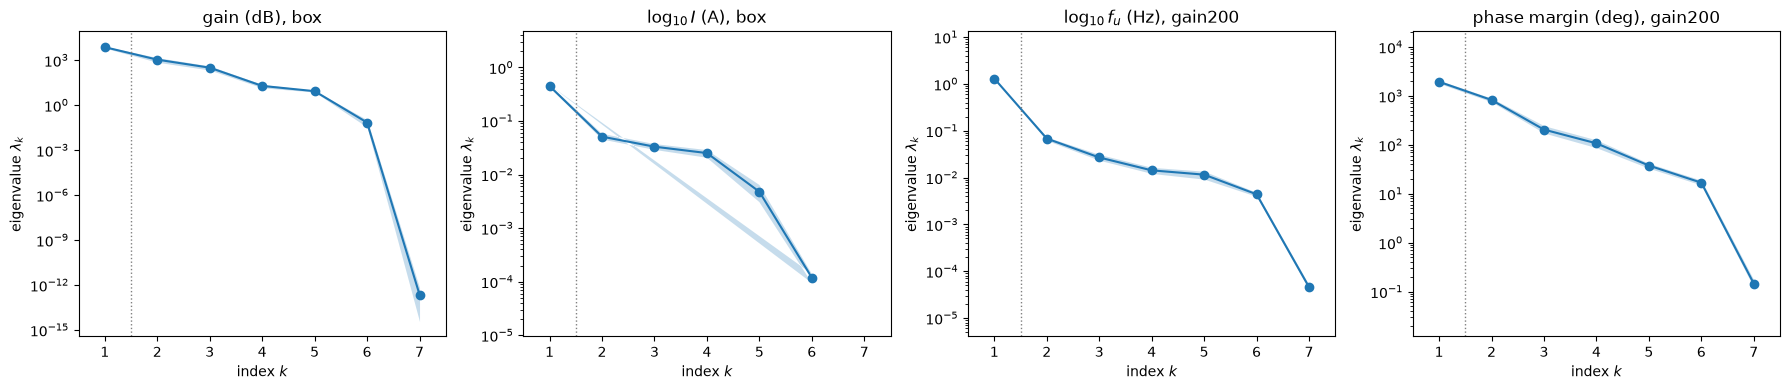

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (k, where) in zip(axes, cases):
    ac.plotting.plot_eigenvalues(S[k][0], ax=ax)
    ax.set_title(f'{QOIS[k]}, {where}')
fig.tight_layout()
plt.close(fig)
for k, where in cases:
    sub = S[k][0]
    lo, hi = np.percentile(sub.bootstrap_eigenvalues, [2.5, 97.5], axis=0)
    print(f'{k:10s}: lambda1/lambda2 = {sub.eigenvalues[0] / sub.eigenvalues[1]:.1f}, '
          f'lambda2/lambda3 = {sub.eigenvalues[1] / sub.eigenvalues[2]:.1f}; bootstrap 95 % lambda1 '
          f'[{lo[0]:.3g}, {hi[0]:.3g}], lambda2 [{lo[1]:.3g}, {hi[1]:.3g}], lambda3 [{lo[2]:.3g}, {hi[2]:.3g}]')
    lam = sub.eigenvalues
    print(f'{"":10s}  lambda3/lambda4 = {lam[2] / lam[3]:.1f}, lambda4 bootstrap 95 % [{lo[3]:.3g}, {hi[3]:.3g}]; '
          f'lambda1/trace = {lam[0] / lam.sum():.3f}; eigenvalues below 1e-4 lambda1 (resolution floor): '
          f'{np.flatnonzero(lam < 1e-4 * lam[0]) + 1}')
common_bias = np.array([0, 0, 0, 1, 1, 1, 0]) / np.sqrt(3)       # mn3, mn4, mn5 scaled together
print('w7 of log10_ugbw and pm, |cos| with (mn3 + mn4 + mn5)/sqrt(3): '
      f"{abs(S['log10_ugbw'][0].W[:, 6] @ common_bias):.3f}, {abs(S['pm'][0].W[:, 6] @ common_bias):.3f}; "
      f"w7 of gain_dB and log10_I, |Cc weight|: {abs(S['gain_dB'][0].W[6, 6]):.3f}, {abs(S['log10_I'][0].W[6, 6]):.3f}")
fig

**Gain** (box): $\lambda_1/\lambda_2 = 6.8$, then $\lambda_2/\lambda_3 = 3.4$ and $\lambda_3/\lambda_4 = 16.5$, the largest gap of the spectrum after the third eigenvalue, with the bootstrap intervals of $\lambda_3$ ([219, 407]) and $\lambda_4$ ([14.3, 24.1]) far apart. The first eigenvalue holds 83.8 % of the trace, so one direction dominates, but the gain has a three-dimensional active subspace; we use $n = 3$ for it below, although the gap rule picks 1. **Supply current** (box): $\lambda_1/\lambda_2 = 8.8$ and then ratios of 1.5 and 1.3, a clear one-dimensional gap. **Bandwidth** (gain200): the largest gap, $\lambda_1/\lambda_2 = 19.1$, with tight bootstrap intervals ($\lambda_1$ in [1.28, 1.32], $\lambda_2$ in [0.0621, 0.0734]). **Phase margin** (gain200): $\lambda_1/\lambda_2 = 2.3$ but $\lambda_2/\lambda_3 = 4.0$, and the bootstrap intervals of $\lambda_2$ ([754, 896]) and $\lambda_3$ ([174, 245]) are well apart, so phase margin has a two-dimensional active subspace; we use $n = 2$ for it below, although the gap rule picks 1. The smallest eigenvalues are at or below the resolution floor of the finite differences ($10^{-4}\lambda_1$: the sixth and seventh of gain, the seventh of the others) and are not interpreted quantitatively. Their directions are physical, though: for gain and current the seventh eigenvector is the $C_c$ axis (the DC operating point does not depend on a capacitor, and the gain at 1 Hz hardly does), and for bandwidth and phase margin it is $m_{n3}$, $m_{n4}$, $m_{n5}$ scaled together ($|\cos| = 0.999$ and 1.000), which keeps every mirror ratio and so every current, and changes only parasitic capacitances.

gain_dB   : bootstrap mean subspace distance, n = 1..4: [0.034 0.046 0.014 0.036]
log10_I   : bootstrap mean subspace distance, n = 1..4: [0.016 0.114 0.159 0.029]
log10_ugbw: bootstrap mean subspace distance, n = 1..4: [0.009 0.038 0.089 0.184]
pm        : bootstrap mean subspace distance, n = 1..4: [0.038 0.03  0.103 0.048]


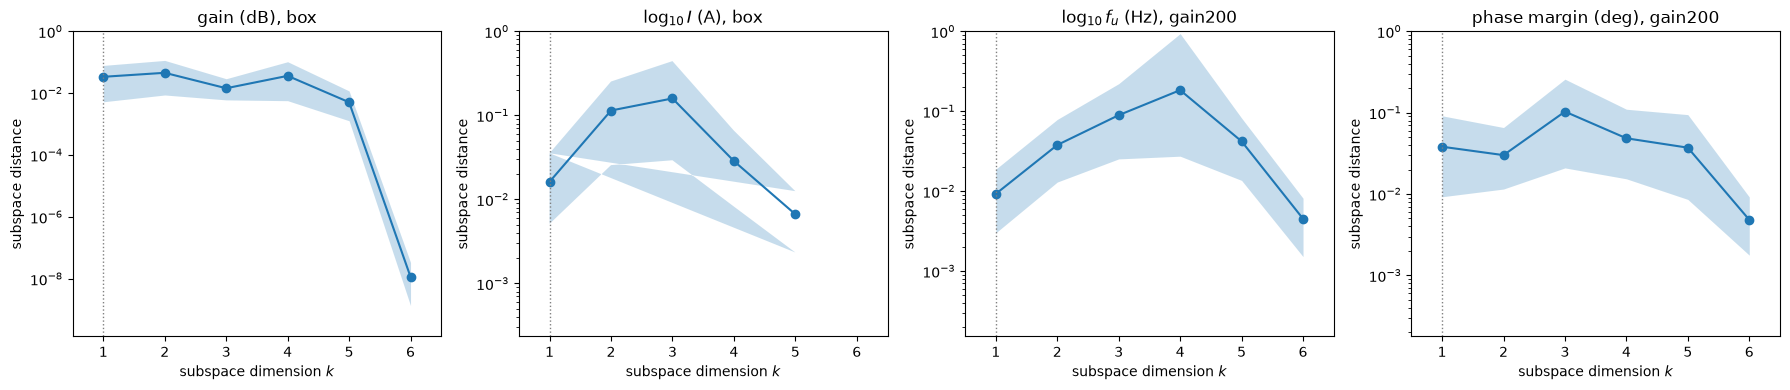

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (k, where) in zip(axes, cases):
    ac.plotting.plot_subspace_errors(S[k][0], ax=ax)
    ax.set_title(f'{QOIS[k]}, {where}')
fig.tight_layout()
plt.close(fig)
for k, where in cases:
    print(f'{k:10s}: bootstrap mean subspace distance, n = 1..4:',
          np.array2string(S[k][0].bootstrap_distances.mean(axis=0)[:4], precision=3))
fig

The bootstrap mean subspace distances for $n = 1$ are 0.016 (current) and 0.009 (bandwidth): the one-dimensional subspaces are well determined. For gain the distance is smallest at the chosen $n = 3$ (0.014, against 0.034 for $n = 1$). For phase margin it is 0.038 for $n = 1$ and 0.030 for $n = 2$.

**Eigenvectors.** The first two eigenvectors of each analysis (plotted), and the third for the gain (printed); the weights are on $\log_{10}$ of the inputs, all scaled alike.

gain_dB    w1: mp1 -0.562, mn1 +0.091, mp3 +0.488, mn3 +0.459, mn4 +0.004, mn5 -0.475, cc_pF -0.000
gain_dB    w2: mp1 +0.345, mn1 -0.007, mp3 +0.394, mn3 -0.366, mn4 +0.684, mn5 -0.353, cc_pF +0.000
gain_dB    w3: mp1 -0.422, mn1 +0.779, mp3 -0.189, mn3 -0.312, mn4 +0.243, mn5 +0.155, cc_pF +0.000
log10_I    w1: mp1 -0.146, mn1 +0.084, mp3 +0.185, mn3 +0.635, mn4 -0.721, mn5 +0.122, cc_pF -0.000
log10_I    w2: mp1 -0.581, mn1 +0.137, mp3 +0.585, mn3 +0.104, mn4 +0.300, mn5 -0.448, cc_pF +0.000
log10_ugbw w1: mp1 -0.166, mn1 +0.095, mp3 +0.171, mn3 +0.574, mn4 -0.662, mn5 +0.112, cc_pF -0.393
log10_ugbw w2: mp1 +0.572, mn1 +0.024, mp3 -0.370, mn3 -0.009, mn4 +0.148, mn5 -0.146, cc_pF -0.701
pm         w1: mp1 -0.424, mn1 -0.181, mp3 +0.654, mn3 -0.455, mn4 +0.096, mn5 +0.374, cc_pF +0.058
pm         w2: mp1 -0.016, mn1 -0.078, mp3 +0.058, mn3 +0.013, mn4 -0.035, mn5 +0.021, cc_pF -0.994
|cos(w1, balance)|: gain 0.993
|cos(w1, log(mn3/(mn4 Cc)))| for f_u: 0.940; |cos(w1, log(sqrt(mn1 mn

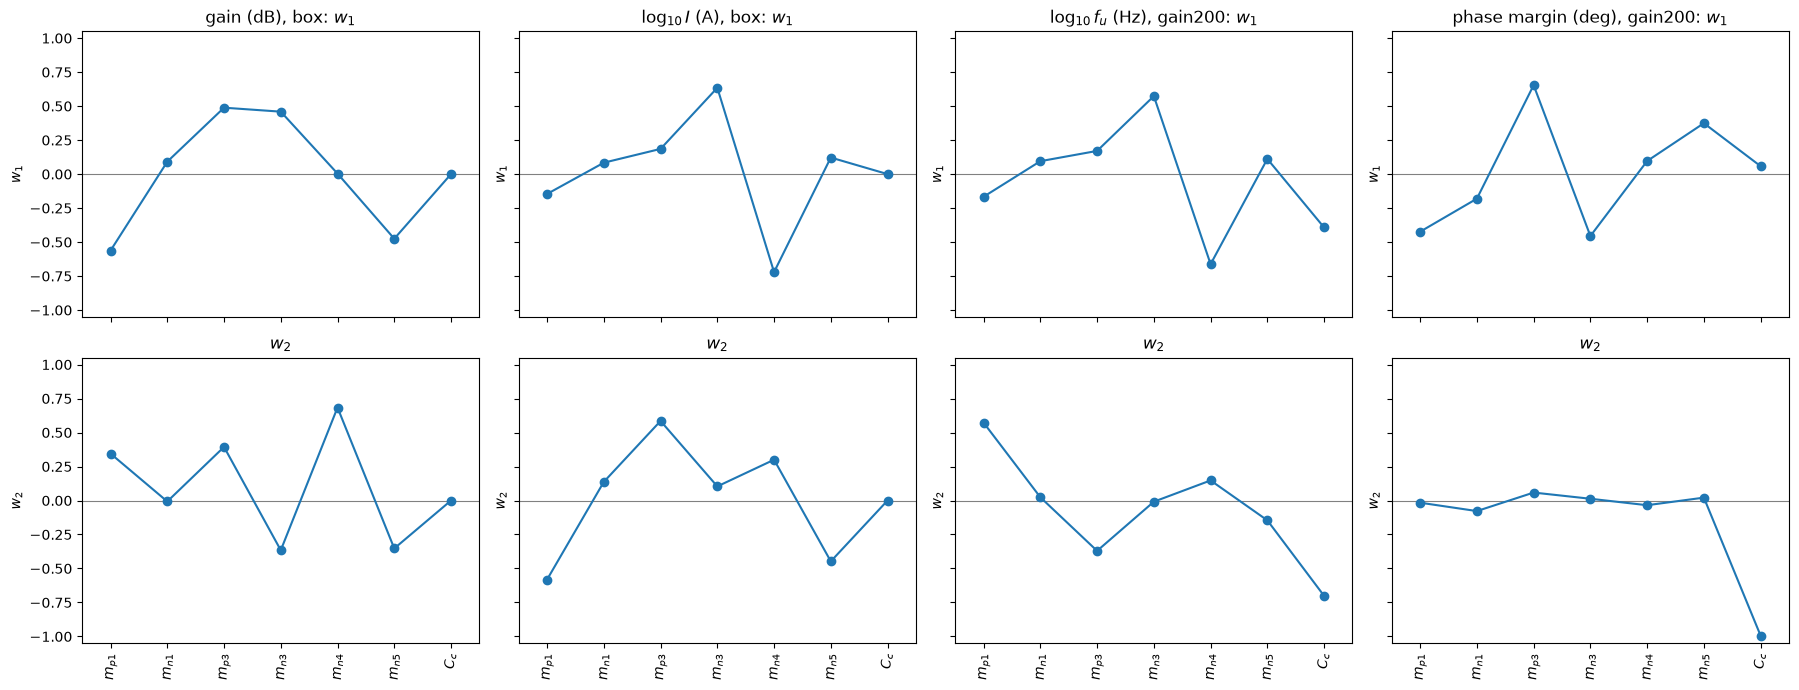

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7), sharey=True)
for col, (k, where) in enumerate(cases):
    ac.plotting.plot_eigenvectors(S[k][0], indices=[0, 1], labels=labels, ax=axes[:, col])
    axes[0, col].set_title(f'{QOIS[k]}, {where}: $w_1$')
    axes[1, col].set_title(f'$w_2$')
fig.tight_layout()
plt.close(fig)
for k, where in cases:
    for i in range(3 if k == 'gain_dB' else 2):
        print(f'{k:10s} w{i + 1}:', ', '.join(f'{n} {w:+.3f}' for n, w in zip(names, S[k][0].W[:, i])))


def cosine(w, v):
    v = np.asarray(v, float)
    return abs(w @ v) / np.linalg.norm(v)


# directions from hand analysis, in z = log10 x (order mp1, mn1, mp3, mn3, mn4, mn5, cc)
balance = [-1, 0, 1, 1, 0, -1, 0]           # log(mp3 mn3 / (mp1 mn5)): second-stage current balance
tail_over_cc = [0, 0, 0, 1, -1, 0, -1]      # log(mn3 / (mn4 Cc)): tail current over Cc (f_u in weak inversion)
gm_over_cc = [0, .5, 0, .5, -.5, 0, -1]     # log(sqrt(mn1 mn3 / mn4) / Cc): f_u in strong inversion
print(f'|cos(w1, balance)|: gain {cosine(S["gain_dB"][0].W[:, 0], balance):.3f}')
print(f'|cos(w1, log(mn3/(mn4 Cc)))| for f_u: {cosine(S["log10_ugbw"][0].W[:, 0], tail_over_cc):.3f}; '
      f'|cos(w1, log(sqrt(mn1 mn3/mn4)/Cc))|: {cosine(S["log10_ugbw"][0].W[:, 0], gm_over_cc):.3f}')

Xb = data['box'][0]
I_hand = op.HELD['ibias_uA'] * 1e-6 * (1 + Xb[:, 3] / Xb[:, 4] + Xb[:, 5] / Xb[:, 4])
rel = I_hand / Fb[:, 3] - 1
Xg = data['gain200'][0]
rel_a = op.HELD['ibias_uA'] * 1e-6 * (1 + Xg[:, 3] / Xg[:, 4] + Xg[:, 5] / Xg[:, 4]) / Fa[:, 3] - 1
print(f'I: mirror-ratio formula vs ngspice, |relative error| median {np.median(np.abs(rel)):.2f} on the box '
      f'(90th percentile {np.percentile(np.abs(rel), 90):.2f}), {np.median(np.abs(rel_a)):.3f} on gain200 '
      f'(90th percentile {np.percentile(np.abs(rel_a), 90):.3f})')
print(f'PM: corr(PM, log10 Cc) = {np.corrcoef(qa["pm"], Za[:, 6])[0, 1]:+.3f}, corr(PM, log10 mp3) = '
      f'{np.corrcoef(qa["pm"], Za[:, 2])[0, 1]:+.3f}, corr(PM, log10 mn3) = {np.corrcoef(qa["pm"], Za[:, 3])[0, 1]:+.3f}')
fig

**Gain.** $\mathbf w_1$ has four large weights, $m_{p1}$ $-0.562$, $m_{p3}$ $+0.488$, $m_{n3}$ $+0.459$ and $m_{n5}$ $-0.475$, and at most 0.091 elsewhere: it is the balance variable $\log(m_{p3}m_{n3}/(m_{p1}m_{n5}))$ of the hand analysis, $|\cos| = 0.993$. The gain depends on device sizes mainly through whether the second-stage currents match. $\mathbf w_2$ is led by the bias device $m_{n4}$ ($+0.684$), and $\mathbf w_3$ by the input pair $m_{n1}$ ($+0.779$, with $m_{p1}$ $-0.422$), which sets the first stage's transconductance per unit current; $C_c$ has no weight in any of the three.

**Supply current.** $\mathbf w_1$ is led by $m_{n4}$ ($-0.721$) and $m_{n3}$ ($+0.635$): the tail-to-reference mirror ratio. The mirror-ratio formula is within a median 3.7 % of ngspice on the gain200 designs (90th percentile 12.7 %), but not on the box (median 23 %, 90th percentile 293 %), where many designs have their output at a rail and devices out of saturation.

**Bandwidth.** $\mathbf w_1$ is led by $m_{n4}$ ($-0.662$), $m_{n3}$ ($+0.574$) and $C_c$ ($-0.393$); the input pair $m_{n1}$ has only $+0.095$. Its cosine with $\log(m_{n3}/(m_{n4}C_c))$, tail current over $C_c$, is 0.940, against 0.800 with the square-law form $\log(\sqrt{m_{n1}m_{n3}/m_{n4}}/C_c)$; so $f_u$ follows the tail current more closely than the square law predicts, as it would for input devices in moderate or weak inversion.

**Phase margin.** $\mathbf w_1$ weights $m_{p3}$ ($+0.654$), $m_{n3}$ ($-0.455$), $m_{p1}$ ($-0.424$) and $m_{n5}$ ($+0.374$): a stronger second stage (larger $m_{p3}$ and its load $m_{n5}$) moves the second pole and the zero up, while more tail current raises $f_u$; the correlations of PM with $\log_{10} m_{p3}$ and $\log_{10} m_{n3}$ are $+0.476$ and $-0.473$. $\mathbf w_2$ is almost $C_c$ alone ($-0.994$), yet the correlation of PM with $\log_{10} C_c$ is only $-0.099$: $C_c$ acts in two opposing ways, lowering $f_u$ (more margin) and lowering the right-half-plane zero (less margin), so PM is not monotone in it.

**Sufficient summary plots.** Each QoI against its first active variable $y_1 = \mathbf w_1^T\mathbf x$ (normalized $\mathbf x$), and phase margin also against $(y_1, y_2)$. The bandwidth and phase-margin panels use the gain200 set, whose inputs are correlated (largest |correlation| 0.534, printed above).

box, top 5 % of gain (>= 47.1 dB): balance variable log10(mp3 mn3/(mp1 mn5)) median 0.332, range [0.129, 0.723] (hand analysis: log10 2 = 0.301); over the box [-3.52, 3.67]


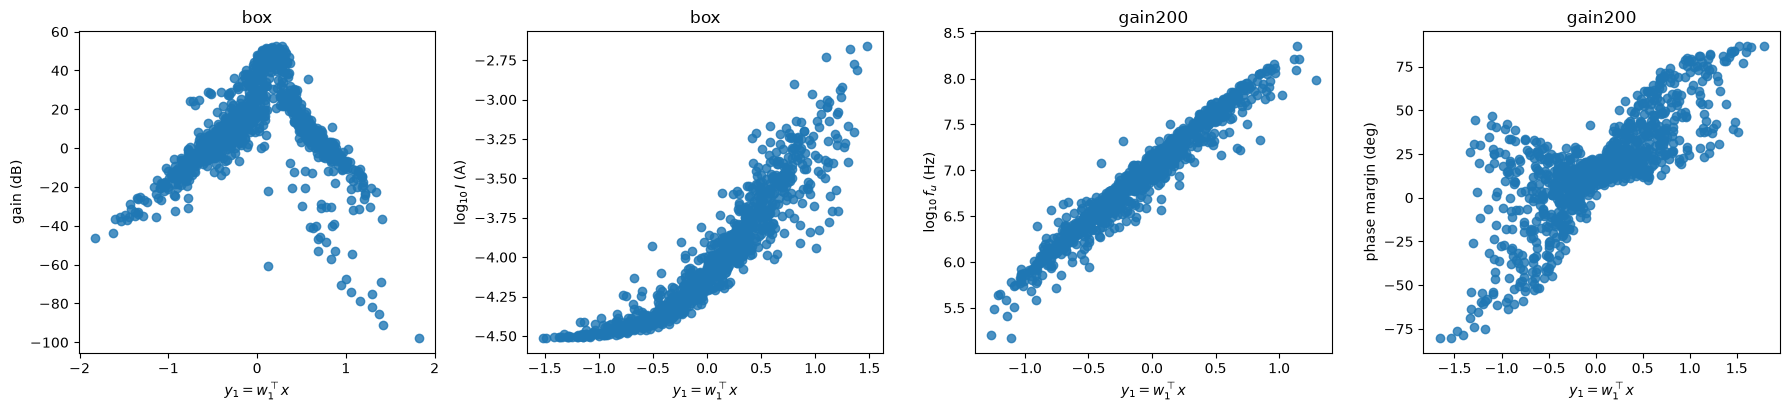

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, (k, where) in zip(axes, cases):
    sub, Zs, f = S[k]
    ac.plotting.plot_sufficient_summary(sub, X=Zs, f=f, dims=1, qoi_label=QOIS[k], ax=ax)
    ax.set_title(where)
fig.tight_layout()
plt.close(fig)
# where the gain peaks along the balance variable
b = np.log10(Xb[:, 2] * Xb[:, 3] / (Xb[:, 0] * Xb[:, 5]))
top = q['gain_dB'] >= np.percentile(q['gain_dB'], 95)
print(f'box, top 5 % of gain (>= {np.percentile(q["gain_dB"], 95):.1f} dB): balance variable '
      f'log10(mp3 mn3/(mp1 mn5)) median {np.median(b[top]):.3f}, range [{b[top].min():.3f}, {b[top].max():.3f}] '
      f'(hand analysis: log10 2 = {np.log10(2):.3f}); over the box [{b.min():.2f}, {b.max():.2f}]')
fig

PM vs y1 (cubic, LOO residuals): y1 < -0.5 at 197 designs, rms 31.7 deg, 59.6% of the squared residual; y1 >= -0.5: rms 12.9 deg


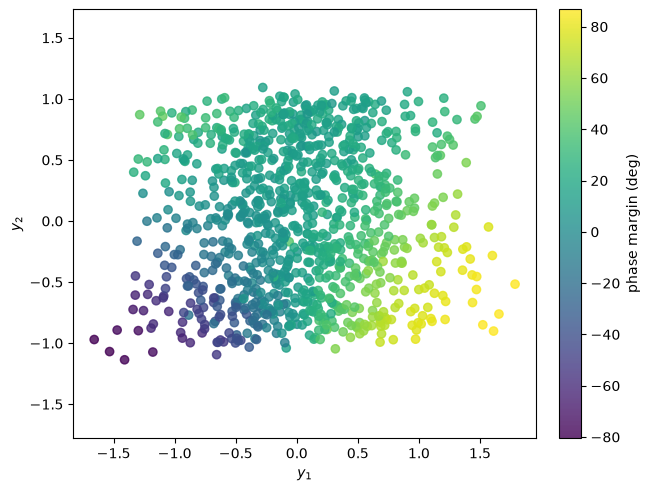

In [11]:
sub2 = ac.with_dimension(S['pm'][0], 2)
fig, ax = ac.plotting.plot_sufficient_summary(sub2, X=Za, f=qa['pm'], dims=2, qoi_label='phase margin (deg)')
plt.close(fig)
# where the one-variable band of PM is wide: leave-one-out residuals of a cubic in y1
s1 = ac.fit_surrogate(X=Za, f=qa['pm'], space=space, subspace=ac.with_dimension(S['pm'][0], 1), kind='poly', degree=3)
y1, r1 = s1.Y[:, 0], s1.loo_residuals
left = y1 < -0.5
print(f'PM vs y1 (cubic, LOO residuals): y1 < -0.5 at {left.sum()} designs, rms {np.sqrt(np.mean(r1[left]**2)):.1f} deg, '
      f'{np.sum(r1[left]**2) / np.sum(r1**2):.1%} of the squared residual; y1 >= -0.5: rms {np.sqrt(np.mean(r1[~left]**2)):.1f} deg')
fig

The gain rises to a peak and falls on both sides of it: the top 5 % of gains (at least 47.1 dB) have a balance variable $\log_{10}(m_{p3}m_{n3}/(m_{p1}m_{n5}))$ between 0.129 and 0.723 (median 0.332), close to the hand-analysis value $\log_{10}2 = 0.301$, while over the box it ranges from $-3.52$ to $3.67$. The scatter about the peak, and the outliers below it, come from the remaining directions ($\mathbf w_2$ weights the bias device $m_{n4}$, 0.684, which sets how hard the output is pushed to a rail). The current is a tight, monotone function of $y_1$, and $\log_{10} f_u$ on the gain200 set is close to linear in $y_1$. Phase margin against $y_1$ alone has a wide band, widest where $y_1 < -0.5$: those 197 designs have a leave-one-out residual of 31.7° rms about a cubic in $y_1$, against 12.9° elsewhere, and carry 59.6 % of the squared residual. The two-dimensional plot resolves the band into a smooth surface. Of the 1000 gain200 designs, 183 have negative phase margin (unstable in unity feedback) and 72 reach the paper's 60°.

**How the bandwidth and phase-margin subspaces depend on the gain threshold.** The gain200 set conditions on the paper's lower gain target. The box set holds designs at every gain, so its subsets with gain above other thresholds show what that choice does (no bootstrap; the subsets are small).

In [12]:
ref = {k: S[k][0].W[:, 0] for k in ('log10_ugbw', 'pm')}
print(f"{'box subset':>16s} {'M':>4s}  " + '  '.join(f'{k}: l1/l2, |cos(w1, gain200 w1)|' for k in ref))
for label, sel in [('gain > 1', Fb[:, 0] > 1), ('gain >= 10', Fb[:, 0] >= 10), ('gain >= 50', Fb[:, 0] >= 50),
                   ('gain >= 100', Fb[:, 0] >= 100), ('gain >= 200', Fb[:, 0] >= 200)]:
    row = []
    for k in ref:
        s = ac.active_subspace(space=space, X=Z[sel], f=q[k][sel], grads=dq[k][sel])
        row.append(f'{s.eigenvalues[0] / s.eigenvalues[1]:6.1f}, {abs(s.W[:, 0] @ ref[k]):.3f}')
    print(f'{label:>16s} {sel.sum():4d}  ' + '                       '.join(row))

      box subset    M  log10_ugbw: l1/l2, |cos(w1, gain200 w1)|  pm: l1/l2, |cos(w1, gain200 w1)|
        gain > 1  690    21.8, 0.006                          8.2, 0.208
      gain >= 10  291     2.0, 0.836                          4.5, 0.137
      gain >= 50  148     8.3, 0.997                          2.4, 0.171
     gain >= 100  112    17.1, 0.999                          1.8, 0.997
     gain >= 200   68    25.2, 1.000                          2.1, 0.983


The box designs with gain ≥ 200 V/V, drawn independently of the gain200 set, reproduce its first eigenvectors (|cos| 1.000 for $\log_{10} f_u$ and 0.983 for PM), so the gain200 result is not a sampling accident. But it is a property of the conditioning. The bandwidth direction holds down to gain ≥ 50 (|cos| 0.997) and changes below it (0.836 at gain ≥ 10). The phase-margin direction holds only for gain ≥ 100 (0.997); at gain ≥ 50 or lower its first eigenvector is nearly orthogonal to the gain200 one (|cos| 0.171, 0.137). The phase-margin subspace found here describes high-gain designs only.

### Surrogates

Polynomials in the active variables, fitted by least squares on all samples of each set, with leave-one-out $R^2$. For the gain, whose peak at the balance condition a low-degree polynomial cannot follow, also radial-basis-function surrogates (`kind="rbf"`, quadratic tail, library defaults) in one to three active variables.

gain_dB    (box): n = 1 (degree 3): LOO R^2 = 0.611; n = 2 (degree 3): LOO R^2 = 0.743
log10_I    (box): n = 1 (degree 3): LOO R^2 = 0.894; n = 2 (degree 3): LOO R^2 = 0.910
log10_ugbw (gain200): n = 1 (degree 3): LOO R^2 = 0.949; n = 2 (degree 3): LOO R^2 = 0.981
pm         (gain200): n = 1 (degree 3): LOO R^2 = 0.582; n = 2 (degree 3): LOO R^2 = 0.957


gain_dB    (box): poly n = 3 (degree 3): LOO R^2 = 0.778; rbf n = 1: 0.729; rbf n = 2: 0.875; rbf n = 3: 0.940


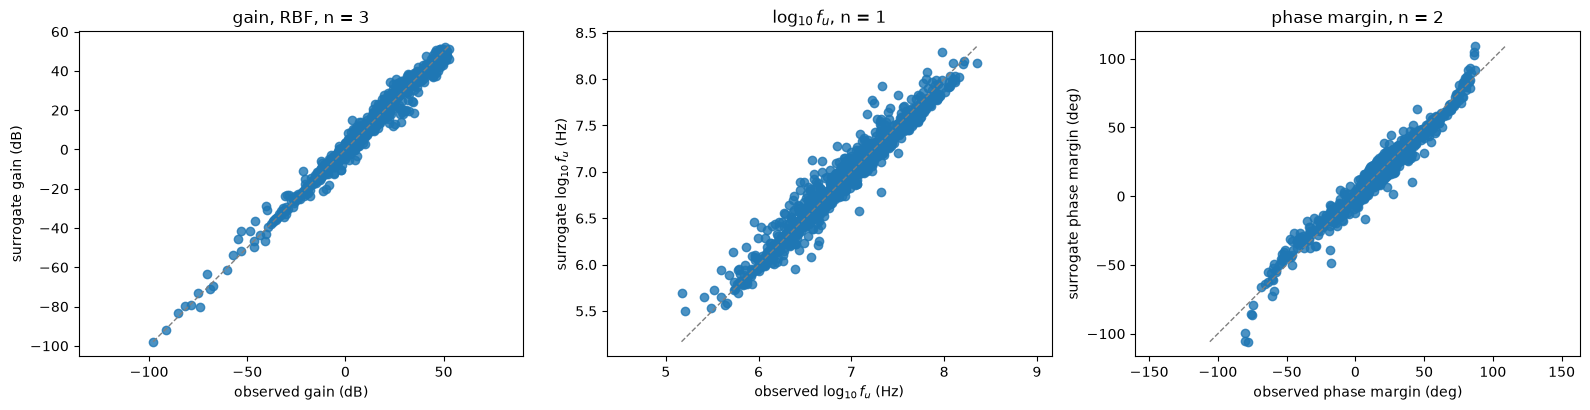

In [13]:
fits = {}
for k, where in cases:
    sub, Zs, f = S[k]
    row = []
    for n, deg in [(1, 3), (2, 3)]:
        s = ac.fit_surrogate(X=Zs, f=f, space=space, subspace=ac.with_dimension(sub, n), kind='poly', degree=deg)
        fits[k, n] = s
        row.append(f'n = {n} (degree {deg}): LOO R^2 = {s.loo_r_squared:.3f}')
    print(f'{k:10s} ({where}):', '; '.join(row))
# gain (box): three active variables, and radial basis functions for its peaked shape
sub_g = S['gain_dB'][0]
row = [f"poly n = 3 (degree 3): LOO R^2 = {ac.fit_surrogate(X=Z, f=q['gain_dB'], space=space, subspace=ac.with_dimension(sub_g, 3), kind='poly', degree=3).loo_r_squared:.3f}"]
for n in (1, 2, 3):
    fits['gain_dB', n, 'rbf'] = ac.fit_surrogate(X=Z, f=q['gain_dB'], space=space, subspace=ac.with_dimension(sub_g, n),
                                                 kind='rbf', degree=2)
    row.append(f"rbf n = {n}: {fits['gain_dB', n, 'rbf'].loo_r_squared:.3f}")
print('gain_dB    (box):', '; '.join(row))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
ac.plotting.plot_surrogate_fit(fits['gain_dB', 3, 'rbf'], X=Z, f=q['gain_dB'], qoi_label=QOIS['gain_dB'], ax=axes[0])
ac.plotting.plot_surrogate_fit(fits['log10_ugbw', 1], X=Za, f=qa['log10_ugbw'], qoi_label=QOIS['log10_ugbw'], ax=axes[1])
ac.plotting.plot_surrogate_fit(fits['pm', 2], X=Za, f=qa['pm'], qoi_label=QOIS['pm'], ax=axes[2])
axes[0].set_title('gain, RBF, n = 3'); axes[1].set_title(r'$\log_{10} f_u$, n = 1'); axes[2].set_title('phase margin, n = 2')
fig.tight_layout()
plt.close(fig)
fig

A cubic in $y_1$ reaches a leave-one-out $R^2$ of 0.949 for $\log_{10} f_u$ and 0.894 for $\log_{10} I$; two active variables add little (0.981 and 0.910). For phase margin the cubic in $(y_1, y_2)$ reaches 0.957, against 0.582 in $y_1$ alone, which confirms $n = 2$. The gain is the hardest for polynomials: a cubic reaches 0.611 in $y_1$, 0.743 in $(y_1, y_2)$ and 0.778 in $(y_1, y_2, y_3)$, because its peak at the balance condition is sharp. Radial basis functions follow the peak: 0.729, 0.875 and 0.940 for $n = 1, 2, 3$. So the weak one-variable fit has two causes, the surrogate class and the dimension; with three active variables the gain is well described, as its spectrum suggests.

### Comparison with the paper

[[1]][R1] is a design-automation study, not a sensitivity study: it reports no eigenvalues, sensitivities or sampled specifications for this circuit. The quantities it does report, and ours where we have them:

In [14]:
spec = ((Fa[:, 0] <= 400) & (Fa[:, 1] >= 1e6) & (Fa[:, 1] <= 2.5e7) & (Fa[:, 2] >= 60)
        & (Fa[:, 3] >= 1e-4) & (Fa[:, 3] <= 1e-2))
loose = (Fa[:, 1] >= 1e6) & (Fa[:, 2] >= 60) & (Fa[:, 3] >= 1e-4) & (Fa[:, 3] <= 1e-2)
p200 = len(Fa) / draws
print(f'gain200 set: inside every target range (gain 200-400 V/V, f_u 1e6-2.5e7 Hz, PM >= 60 deg, '
      f'I 0.1-10 mA): {spec.sum()} of {len(Fa)}; meeting f_u >= 1e6, PM >= 60, I in range: {loose.sum()}')
print(f'fraction of the log-uniform box inside every target range: {p200:.4f} x {spec.mean():.4f} = {p200 * spec.mean():.2e}')
low = Fa[:, 3] < 1e-4
print(f'gain200: corr(log10 I, log10 f_u) = {np.corrcoef(qa["log10_I"], qa["log10_ugbw"])[0, 1]:.3f}; '
      f'I < 0.1 mA at {low.sum()} designs: f_u >= 10 MHz at {np.mean(Fa[low, 1] >= 1e7):.1%}, '
      f'f_u >= 25 MHz at {np.mean(Fa[low, 1] >= 2.5e7):.1%}; I >= 0.1 mA at {(~low).sum()}: '
      f'{np.mean(Fa[~low, 1] >= 1e7):.1%} and {np.mean(Fa[~low, 1] >= 2.5e7):.1%}')
sI = ac.active_subspace(space=space, X=Za, f=qa['log10_I'], grads=dqa['log10_I'])
print(f'gain200: |w1(log10 I) . w1(log10 f_u)| = {abs(sI.W[:, 0] @ S["log10_ugbw"][0].W[:, 0]):.3f}; '
      f'w1(log10 I) = {np.round(sI.W[:, 0], 3)}, lambda1/lambda2 = {sI.eigenvalues[0] / sI.eigenvalues[1]:.1f}')
print(f'Total run time: {time.perf_counter() - t_start:.0f} s')

gain200 set: inside every target range (gain 200-400 V/V, f_u 1e6-2.5e7 Hz, PM >= 60 deg, I 0.1-10 mA): 32 of 1000; meeting f_u >= 1e6, PM >= 60, I in range: 33
fraction of the log-uniform box inside every target range: 0.0809 x 0.0320 = 2.59e-03
gain200: corr(log10 I, log10 f_u) = 0.783; I < 0.1 mA at 677 designs: f_u >= 10 MHz at 22.5%, f_u >= 25 MHz at 3.0%; I >= 0.1 mA at 323: 82.0% and 51.1%
gain200: |w1(log10 I) . w1(log10 f_u)| = 0.916; w1(log10 I) = [ 0.216 -0.037 -0.226 -0.597  0.722 -0.149  0.   ], lambda1/lambda2 = 20.2
Total run time: 14 s


| quantity | paper [[1]][R1] | this notebook |
|---|---|---|
| design-space size | $10^{14}$ (Sec. III.B) | AutoCkt's grids (`np.arange`): $99^6 \times 99 = 9.3\times10^{13}$ (m = 1…99, $C_c$ = 0.1…9.9 pF); here relaxed to the continuous log box [1, 100], [0.1, 10] pF |
| transistor sizes | width [1, 100, 1] × 0.5 µm | AutoCkt netlist: multiplier $m$ of a 0.5 µm / 90 nm device; real $m \in [1, 100]$ |
| simulator | "a simulator that works on predictive technology models" (the AutoCkt README: ngspice release 27) | ngspice-42 |
| fraction of designs with gain ≥ 200 V/V | not reported | 0.0809 of the log-uniform box (1000 of 12367 draws) |
| fraction inside every target range (gain 200–400 V/V, $f_u$ 1–25 MHz, PM ≥ 60°, $I$ 0.1–10 mA) | "random generation of parameters … infeasible" (no number) | 32 of the 1000 gain200 designs, $2.6\times10^{-3}$ of the box |
| random RL agent reaching a target | 38/1000 (Table II) | not comparable (no agent here) |
| unreached targets lie where the bias current is very low (Fig. 8, p. 4) | hypothesis | among gain200 designs, corr($\log_{10} I$, $\log_{10} f_u$) = 0.783; $f_u \ge 25$ MHz at 3.0 % of the 677 designs with $I < 0.1$ mA, against 51.1 % of the 323 with $I \ge 0.1$ mA |
| sensitivities, eigenvalues, input importance | not reported | above |

The low acceptance rates quantify the paper's remark that random sampling is a poor way to meet the targets: on the log-uniform box only about one design in 390 meets all of them ($2.6\times10^{-3}$). The active subspaces add a reason: the gain target confines designs to a thin slab around the balance condition, a single direction in the seven-dimensional box (the balance variable has standard deviation 0.122 in the gain200 set, against 1.161 on the box). Among designs that meet the gain target, bandwidth and current are driven mainly by the same direction, the tail-current mirror ratio: their first eigenvectors have $|\mathbf w_1^{(I)}\cdot\mathbf w_1^{(f_u)}| = 0.916$ (the current's own $\lambda_1/\lambda_2$ on this set is 20.2). A high-bandwidth target therefore needs current, which is consistent with the paper's observation that the targets AutoCkt did not reach are those with very low bias current.

### References

[1] K. Settaluri, A. Haj-Ali, Q. Huang, K. Hakhamaneshi and B. Nikolic, "AutoCkt: Deep reinforcement learning of analog circuit designs," *2020 Design, Automation & Test in Europe Conference & Exhibition (DATE)*, IEEE, 2020, pp. 490–495. [doi:10.23919/DATE48585.2020.9116200](https://doi.org/10.23919/DATE48585.2020.9116200). (Read as the preprint arXiv:2001.01808v2.)

[2] P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM, Philadelphia, 2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860)

[3] P. G. Constantine, E. Dow and Q. Wang, "Active subspace methods in theory and practice: applications to kriging surfaces," *SIAM J. Sci. Comput.* 36(4):A1500–A1524, 2014. [doi:10.1137/130916138](https://doi.org/10.1137/130916138)

[4] K. Settaluri et al., AutoCkt source code, <https://github.com/ksettaluri6/AutoCkt> (commit a6c8a61, 2022; netlist `eval_engines/ngspice/ngspice_inputs/netlist/two_stage_opamp.cir`, model card `spice_models/45nm_bulk.txt`).

[5] Y. Cao, T. Sato, M. Orshansky, D. Sylvester and C. Hu, "New paradigm of predictive MOSFET and interconnect modeling for early circuit simulation," *Proc. IEEE 2000 Custom Integrated Circuits Conference*, pp. 201–204, 2000. [doi:10.1109/CICC.2000.852648](https://doi.org/10.1109/CICC.2000.852648)

[6] ngspice, open-source mixed-signal circuit simulator, version 42, <https://ngspice.sourceforge.io>.

[R1]: https://doi.org/10.23919/DATE48585.2020.9116200
[R2]: https://doi.org/10.1137/1.9781611973860
[R3]: https://doi.org/10.1137/130916138
[R4]: https://github.com/ksettaluri6/AutoCkt
[R5]: https://doi.org/10.1109/CICC.2000.852648

### Acknowledgments

The paper's work was supported by DARPA CRAFT (HR0011-16-C-0052), ADEPT, and BWRC member companies ([[1]][R1], Sec. V).